In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sys
sys.path.insert(0, "../src")   # shared grid + map helpers live in src/grid.py
from grid import (LON_MIN, LON_MAX, LAT_MIN, LAT_MAX, RES, lon_edges, lat_edges,
                  lon_c, lat_c, nx, ny, cell_index, style_map, proj)

In [2]:
DATA_DIR = Path("../data")      # data, tables, results (parquet, npz, csv, json)
FIG_DIR  = Path("../figures")   # all figures (png)

# Each notebook writes to its own subfolder; inputs come from earlier notebooks' folders
OUT_DIR = DATA_DIR / "03_aggregation_and_means"
FIG_OUT = FIG_DIR / "03_aggregation_and_means"
DIR_01  = DATA_DIR / "01_data_prep_roni_gdp"          # kuroshio_obs_clean, roni_phase
OUT_DIR.mkdir(parents=True, exist_ok=True)
FIG_OUT.mkdir(parents=True, exist_ok=True)

In [3]:
# Cleaned, RONI-tagged Kuroshio observations (01_data_prep_roni_gdp)
df = pd.read_parquet(DIR_01 / "kuroshio_obs_clean.parquet")

# Velocity analysis uses drogued drifters only (flag cross-checked against drogue loss date)
df_drogued = df[df["drogued"]].copy()

# Input check: notebook 01 already drops drogued hours with a missing velocity component
assert len(df_drogued) == 2_135_791 and df_drogued["id"].nunique() == 1_177
assert df_drogued[["ve", "vn"]].notna().all().all()

print(f"{len(df):,} obs total | {len(df_drogued):,} drogued from {df_drogued['id'].nunique():,} drifters")

summary = {}

4,623,446 obs total | 2,135,791 drogued from 1,177 drifters


### Aggregation

Aggregate to one row per drifter per cell. Hourly observations from one drifter are strongly correlated, so later uncertainty steps resample drifters, not hours. Sums are stored so any set of drifters recombines into an exact mean.

In [4]:
def aggregate_by_drifter(d, value_cols):
    """One row per (cell, drifter, ENSO phase): hour count and sum of each variable.
    The drifter is the independent unit, so later steps resample these rows."""
    d = d.dropna(subset=value_cols)                       # only rows with valid values
    iy, ix = cell_index(d)                                # same cells as the support maps
    tmp = pd.DataFrame({"iy": iy, "ix": ix, "id": d["id"].values, "enso": d["enso"].values})
    for c in value_cols:
        tmp[c] = d[c].values
    return (tmp.groupby(["iy", "ix", "id", "enso"])
               .agg(n=(value_cols[0], "size"),                        # hours in this cell
                    **{f"sum_{c}": (c, "sum") for c in value_cols})   # sum of each variable
               .reset_index())


agg_vel = aggregate_by_drifter(df_drogued, ["ve", "vn"])   # velocity: drogued only
agg_sst = aggregate_by_drifter(df, ["sst"])                # SST: all drifters

summary["agg_vel_rows"] = int(len(agg_vel))
summary["agg_sst_rows"] = int(len(agg_sst))
print(f"velocity: {len(agg_vel):,} rows | sst: {len(agg_sst):,} rows")

velocity: 23,722 rows | sst: 48,153 rows


In [5]:
agg_vel.to_parquet(OUT_DIR / "agg_vel_1deg.parquet")
agg_sst.to_parquet(OUT_DIR / "agg_sst_1deg.parquet")

In [6]:
print(agg_vel)
print(agg_sst)

       iy  ix               id     enso    n     sum_ve     sum_vn
0       0   0            49632  Neutral   70  -1.539700   1.969500
1       0   0           139801  El Niño  119  29.830900  -6.839100
2       0   0           139804  El Niño  147  29.963699  12.354700
3       0   0  300234060291780  Neutral   74  14.902200  30.791599
4       0   0  300234060999470  Neutral   76  -6.300600  32.247200
...    ..  ..              ...      ...  ...        ...        ...
23717  24  29  300234065708610  Neutral   49  23.745600  -5.356500
23718  24  29  300234066335930  Neutral    8  -3.767316   2.981386
23719  24  29  300234066431370  Neutral   91  -7.275721  30.663370
23720  24  29  300234067542090  La Niña  114   6.449013 -40.337212
23721  24  29  300534061384140  La Niña   21   6.551003   0.209187

[23722 rows x 7 columns]
       iy  ix               id     enso    n       sum_sst
0       0   0            49632  Neutral   70  21162.810547
1       0   0            55356  Neutral  318  95146.

### CLIMATOLOGY

In [7]:
def cell_means(agg, value_cols):
    """
    Per-cell mean of each variable = total sum / total hours.
    This weights every hourly observation equally (our stated definition).
    Returns 2-D arrays (lat x lon); NaN where a cell has no data.
    """
    g = agg.groupby(["iy", "ix"]).agg(
        n_obs=("n", "sum"),                                        # total hours in the cell
        n_drifters=("id", "nunique"),                              # distinct drifters
        **{f"sum_{c}": (f"sum_{c}", "sum") for c in value_cols})   # summed values
    iy, ix = g.index.get_level_values("iy"), g.index.get_level_values("ix")

    out = {"n_obs": np.zeros((ny, nx)), "n_drifters": np.zeros((ny, nx))}
    out["n_obs"][iy, ix] = g["n_obs"].values
    out["n_drifters"][iy, ix] = g["n_drifters"].values
    for c in value_cols:
        out[f"mean_{c}"] = np.full((ny, nx), np.nan)
        out[f"mean_{c}"][iy, ix] = (g[f"sum_{c}"] / g["n_obs"]).values
    return out


vel = cell_means(agg_vel, ["ve", "vn"])
sst = cell_means(agg_sst, ["sst"])

# Magnitude of the MEAN VELOCITY VECTOR (not the average of hourly speeds)
vel["mean_speed"] = np.hypot(vel["mean_ve"], vel["mean_vn"])

summary["max_mean_speed_ms"] = round(float(np.nanmax(vel["mean_speed"])), 3)
summary["sst_range_c"] = [round(float(np.nanmin(sst["mean_sst"]) - 273.15), 2),
                          round(float(np.nanmax(sst["mean_sst"]) - 273.15), 2)]
print(f"max mean speed: {np.nanmax(vel['mean_speed']):.2f} m/s")
print(f"SST range: {np.nanmin(sst['mean_sst'])-273.15:.1f} to {np.nanmax(sst['mean_sst'])-273.15:.1f} °C")

max mean speed: 1.11 m/s
SST range: 11.3 to 29.9 °C


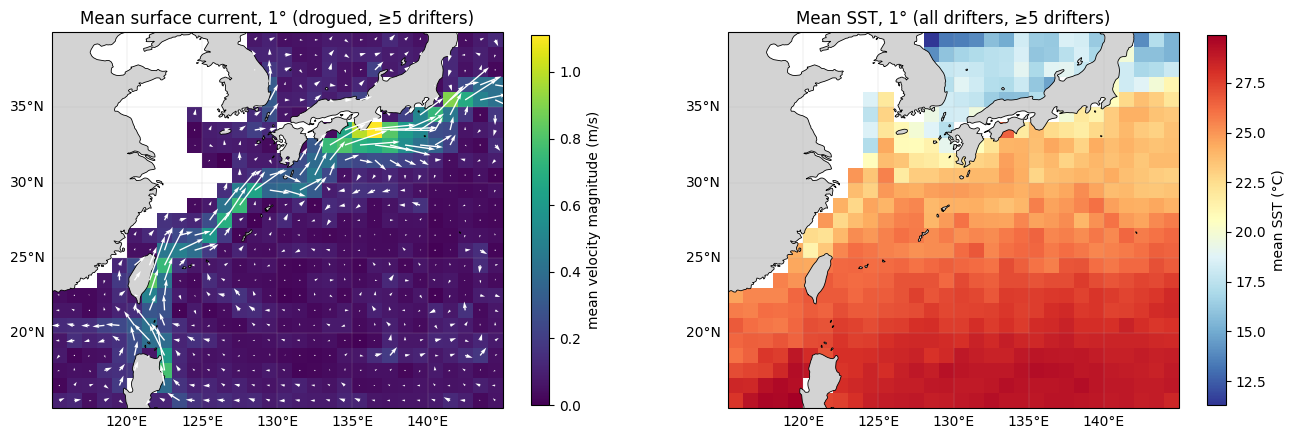

In [8]:
# Display mask (>= 5 drifters) for a quick look only; not part of the method.
# The report versions of these maps, with reliability (N* and U95) marked,
# are drawn in 08_maps_with_reliability.
MIN_DRIFTERS = 5
show_vel = vel["n_drifters"] >= MIN_DRIFTERS
show_sst = sst["n_drifters"] >= MIN_DRIFTERS

fig, axes = plt.subplots(1, 2, figsize=(16, 6), subplot_kw={"projection": proj})

# --- Left: mean current (colour = magnitude, arrows = direction) ---
ax = axes[0]
im = ax.pcolormesh(lon_edges, lat_edges, np.where(show_vel, vel["mean_speed"], np.nan),
                   cmap="viridis", vmin=0, transform=proj)
ax.quiver(lon_c, lat_c,
          np.where(show_vel, vel["mean_ve"], np.nan),
          np.where(show_vel, vel["mean_vn"], np.nan),
          scale=8, width=0.003, color="white", transform=proj, zorder=4)
fig.colorbar(im, ax=ax, label="mean velocity magnitude (m/s)", shrink=0.8)
ax.set_title(f"Mean surface current, {RES:g}° (drogued, ≥{MIN_DRIFTERS} drifters)")

# --- Right: mean SST in °C ---
ax = axes[1]
im = ax.pcolormesh(lon_edges, lat_edges, np.where(show_sst, sst["mean_sst"] - 273.15, np.nan),
                   cmap="RdYlBu_r", transform=proj)
fig.colorbar(im, ax=ax, label="mean SST (°C)", shrink=0.8)
ax.set_title(f"Mean SST, {RES:g}° (all drifters, ≥{MIN_DRIFTERS} drifters)")

for ax in axes:
    style_map(ax)
fig.savefig(FIG_OUT / "climatology_vel_sst_initial.png", dpi=300, bbox_inches="tight")
plt.show()

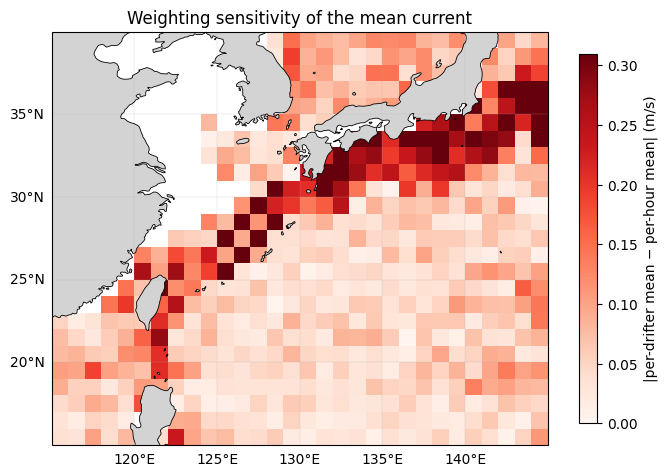

577 cells with >= 2 drifters | median difference: 0.060 m/s | 90th pct: 0.223 m/s | cells > 0.10 m/s: 28%


In [9]:
# --- Weighting sensitivity: equal weight per hour vs equal weight per drifter ---
# Each drifter's own mean in each cell (summing its rows across ENSO phases first)
per_dr = agg_vel.groupby(["iy", "ix", "id"])[["n", "sum_ve", "sum_vn"]].sum()
per_dr["ve"] = per_dr["sum_ve"] / per_dr["n"]
per_dr["vn"] = per_dr["sum_vn"] / per_dr["n"]

# Equal weight per drifter = plain average of the drifter means
dr_mean = per_dr.groupby(level=["iy", "ix"])[["ve", "vn"]].mean()
ve_dr = np.full((ny, nx), np.nan); vn_dr = np.full((ny, nx), np.nan)
iy, ix = dr_mean.index.get_level_values("iy"), dr_mean.index.get_level_values("ix")
ve_dr[iy, ix] = dr_mean["ve"].values
vn_dr[iy, ix] = dr_mean["vn"].values

# Size of the difference between the two mean vectors (m/s), every cell with data
diff = np.hypot(ve_dr - vel["mean_ve"], vn_dr - vel["mean_vn"])
# Weighting statistics and the colour cap use every cell with >= 2 drifters
# (the cells that receive a bootstrap interval in 04); the >= 5 mask is for the quick-look plot only
MIN_DRIFTERS_STATS = 2
stats_vel = vel["n_drifters"] >= MIN_DRIFTERS_STATS
assert stats_vel.sum() == 577 and np.isfinite(diff[stats_vel]).all()
diff_stats = diff[stats_vel]
weight_vmax = float(np.percentile(diff_stats, 95))           # colour cap: 95th percentile, >= 2 drifters

diff_show = np.where(show_vel, diff, np.nan)               # display mask only (same as the climatology)

fig, ax = plt.subplots(figsize=(8, 6), subplot_kw={"projection": proj})
im = ax.pcolormesh(lon_edges, lat_edges, diff_show, cmap="Reds", vmin=0,
                   vmax=weight_vmax, transform=proj)
fig.colorbar(im, ax=ax, label="|per-drifter mean − per-hour mean| (m/s)", shrink=0.8)
style_map(ax, "Weighting sensitivity of the mean current")
fig.savefig(FIG_OUT / "weighting_sensitivity_initial.png", dpi=300, bbox_inches="tight")
plt.show()

summary["weighting_diff_ms"] = {"min_drifters": MIN_DRIFTERS_STATS, "n_cells": int(stats_vel.sum()),
                                "median": round(float(np.median(diff_stats)), 4),
                                "p90":    round(float(np.percentile(diff_stats, 90)), 4)}
print(f"{stats_vel.sum()} cells with >= {MIN_DRIFTERS_STATS} drifters | "
      f"median difference: {np.median(diff_stats):.3f} m/s | "
      f"90th pct: {np.percentile(diff_stats, 90):.3f} m/s | "
      f"cells > 0.10 m/s: {(diff_stats > 0.10).mean():.0%}")

In [10]:
# --- Does drifter-weighting make the mean current faster? ---
# Compare the speed of the two mean vectors in every cell with >= MIN_DRIFTERS_STATS (2) drifters
speed_hr = vel["mean_speed"]                     # equal weight per hour
speed_dr = np.hypot(ve_dr, vn_dr)                # equal weight per drifter
JET_SPEED = 0.40                                 # m/s; "jet" cells by hour-weighted speed

def faster_stats(mask):
    d = (speed_dr - speed_hr)[mask]
    return {"n_cells": int(mask.sum()),
            "n_drifter_weighted_faster": int((d > 0).sum()),
            "share_drifter_weighted_faster": round(float((d > 0).mean()), 3),
            "median_diff_ms": round(float(np.median(d)), 4)}

speed_cmp = {"all": faster_stats(stats_vel),
             "jet": faster_stats(stats_vel & (speed_hr > JET_SPEED))}
summary["weighting_speed_comparison"] = {"min_drifters": MIN_DRIFTERS_STATS,
                                         "jet_threshold_ms": JET_SPEED, **speed_cmp}

for name, s in speed_cmp.items():
    print(f"{name:>3}: {s['n_drifter_weighted_faster']}/{s['n_cells']} cells faster under drifter-weighting "
          f"({s['share_drifter_weighted_faster']:.0%}), median difference {s['median_diff_ms']*100:+.1f} cm/s")


all: 515/577 cells faster under drifter-weighting (89%), median difference +4.5 cm/s
jet: 41/41 cells faster under drifter-weighting (100%), median difference +24.8 cm/s


In [11]:
# Save the weighting difference (m/s) for the reliability step, unmasked (masking happens there)
np.save(OUT_DIR / "weighting_diff_1deg.npy", diff)

In [12]:
# --- Extra numbers for the climatology and weighting maps ---
iy_max, ix_max = np.unravel_index(np.nanargmax(vel["mean_speed"]), vel["mean_speed"].shape)
summary["max_mean_speed_cell"] = {"lon": float(lon_c[ix_max]), "lat": float(lat_c[iy_max]),
                                  "n_drifters": int(vel["n_drifters"][iy_max, ix_max])}
summary["n_cells_quicklook_ge5"] = int(show_vel.sum())                        # cells shown on the quick-look maps
summary["weighting_map_vmax_p95_ms"] = round(weight_vmax, 4)                  # 95th percentile, >= 2 drifters
print(summary["max_mean_speed_cell"], summary["n_cells_quicklook_ge5"], summary["weighting_map_vmax_p95_ms"])

{'lon': 136.5, 'lat': 33.5, 'n_drifters': 53} 562 0.3097


In [13]:
# --- Key numbers for Section 3 (aggregation and means) ---
(OUT_DIR / "03_summary.json").write_text(json.dumps(summary, indent=2, ensure_ascii=False))
print(json.dumps(summary, indent=2, ensure_ascii=False))

{
  "agg_vel_rows": 23722,
  "agg_sst_rows": 48153,
  "max_mean_speed_ms": 1.11,
  "sst_range_c": [
    11.3,
    29.89
  ],
  "weighting_diff_ms": {
    "min_drifters": 2,
    "n_cells": 577,
    "median": 0.0596,
    "p90": 0.2235
  },
  "weighting_speed_comparison": {
    "min_drifters": 2,
    "jet_threshold_ms": 0.4,
    "all": {
      "n_cells": 577,
      "n_drifter_weighted_faster": 515,
      "share_drifter_weighted_faster": 0.893,
      "median_diff_ms": 0.0451
    },
    "jet": {
      "n_cells": 41,
      "n_drifter_weighted_faster": 41,
      "share_drifter_weighted_faster": 1.0,
      "median_diff_ms": 0.2482
    }
  },
  "max_mean_speed_cell": {
    "lon": 136.5,
    "lat": 33.5,
    "n_drifters": 53
  },
  "n_cells_quicklook_ge5": 562,
  "weighting_map_vmax_p95_ms": 0.3097
}
